# Week (1) Module D: Distributions & Skewness
**Course:** Statistics and Machine Learning

---

### Module Contributor(s)
| Full Name | Role |
|---|---|
| `_______________` | `_______________` |
| `_______________` | `_______________` |

---

### About this Module
This module covers **Tasks 8 and 9** of the Week (1) practical.
Your outputs will be merged with **Modules A, B, and C into the group's final notebook**.

**Background: Day 2 lecture recap:**

A **distribution** describes how data values are spread across their range. 

>Different distributions arise from different data-generating processes:
- **Normal:** Symmetric, bell-shaped. Defined by mean (μ) and standard deviation (σ). Common in measurement errors and biological traits.
- **Uniform:** Every value in a range is equally likely. Common in random number generation and lottery draws.
- **Binomial:** Counts of successes in a fixed number of independent trials, each with probability p.
- **Poisson:** Counts of events occurring in a fixed interval at a known average rate λ.

**Skewness** measures the asymmetry of a distribution. 
- Positive skew = long right tail (mean > median). 
- Negative skew = long left tail (mean < median).

**Dataset:** Pima Indians Diabetes —> DOI: https://www.openml.org/d/37

---
> Cells marked `# TODO` require code. Cells marked `✍️` require a written response.

---
# Task 8: Recognise and Generate Distributions

Before fitting models to data, you need to recognise what kind of distribution your data follows. Here you will both generate synthetic distributions and compare them to real features in the diabetes dataset.

> **Goal:** Generate, visualise, and compare the four key distributions from the lecture. Match real dataset features to their closest theoretical distribution.

In [1]:
# ── Task 8 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# scipy.stats is needed for:
#   stats.norm.pdf()  -> compute the Normal probability density function
#   stats.skew()      -> compute skewness of an array
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')

# Wide default figure size suits side-by-side distribution comparison plots.
plt.rcParams['figure.figsize'] = (14, 4)

# Fix the random seed so all students generate the same synthetic datasets.
# Every np.random call after this line is reproducible.
np.random.seed(42)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# N is set to match the real dataset size (768 rows) so synthetic and real
# distributions are visually comparable — same number of observations.
N = 768
print(f'Ready (N = {N})')


Ready (N = 768)


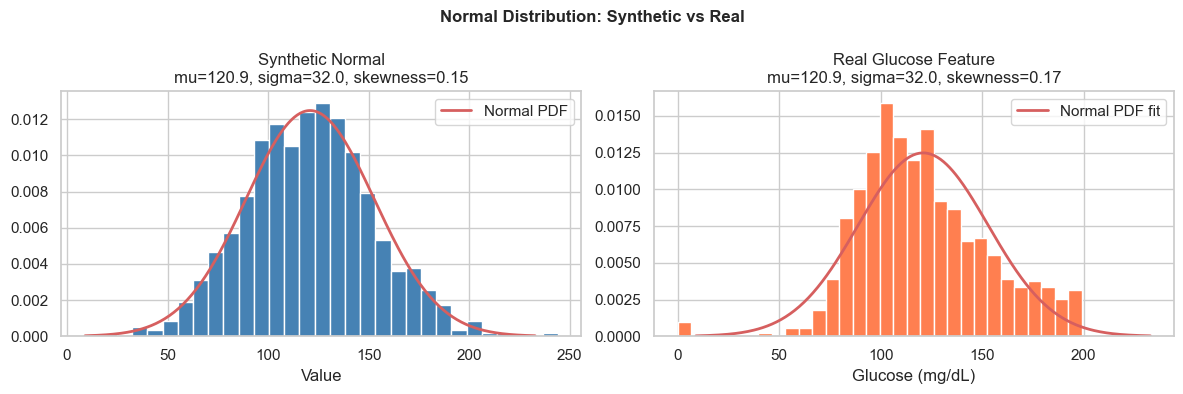

In [2]:
# Provided: generate a synthetic Normal distribution and compare it to real Glucose

# Use the real Glucose mean and std as parameters so the synthetic distribution
# is directly comparable to the real feature in the right panel.
mu, sigma = df['Glucose'].mean(), df['Glucose'].std()

# np.random.normal() draws N samples from N(mu, sigma).
# Because np.random.seed(42) was set in the setup cell, this is reproducible.
normal_data = np.random.normal(loc=mu, scale=sigma, size=N)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Left panel: synthetic Normal ---
# density=True rescales the y-axis from raw counts to probability density,
# so the histogram bars and the PDF curve share the same y-axis and are comparable.
axes[0].hist(normal_data, bins=30, color='steelblue', edgecolor='white', density=True)

# The Probability Density Function fit (PDF) curve is a mathematical function of the PARAMETERS (mu, sigma),
# not of any particular random sample.
# We define x using mu +/- 3.5*sigma to cover >99.9% of the Normal distribution,
# regardless of what the random sample happened to produce at its extremes.
x = np.linspace(mu - 3.5 * sigma, mu + 3.5 * sigma, 300)

# Normal Probability Density Function (Normal PDF)
# stats.norm.pdf(x, mu, sigma) evaluates the Normal PDF:
#   f(x) = (1 / (sigma * sqrt(2*pi))) * exp(-0.5 * ((x - mu) / sigma)^2)
# at each point in x. The result is a smooth bell curve.
axes[0].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', lw=2, label='Normal PDF')
axes[0].set_title(f'Synthetic Normal\nmu={mu:.1f}, sigma={sigma:.1f}, skewness={stats.skew(normal_data):.2f}')
axes[0].set_xlabel('Value')
axes[0].legend()

# --- Right panel: real Glucose with its own fitted PDF ---
# We compute mu_g and sigma_g separately from the real data.
# This fitted PDF shows how well a Normal distribution describes the real feature.
# If the bars deviate from the curve, the feature is not perfectly Normal.
mu_g, sigma_g = df['Glucose'].mean(), df['Glucose'].std()
axes[1].hist(df['Glucose'], bins=30, color='coral', edgecolor='white', density=True)
x_g = np.linspace(mu_g - 3.5 * sigma_g, mu_g + 3.5 * sigma_g, 300)
axes[1].plot(x_g, stats.norm.pdf(x_g, mu_g, sigma_g), 'r-', lw=2, label='Normal PDF fit')
axes[1].set_title(f'Real Glucose Feature\nmu={mu_g:.1f}, sigma={sigma_g:.1f}, skewness={stats.skew(df["Glucose"]):.2f}')
axes[1].set_xlabel('Glucose (mg/dL)')
axes[1].legend()

plt.suptitle('Normal Distribution: Synthetic vs Real', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


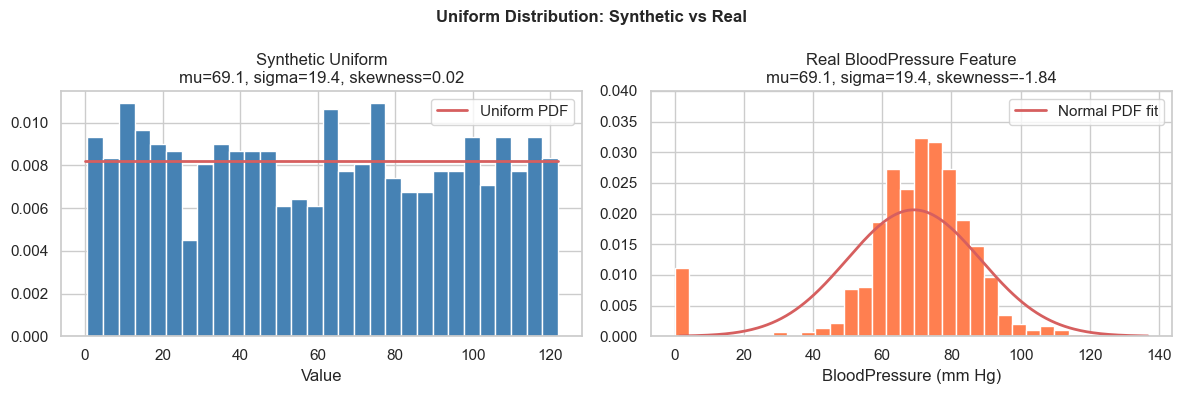

In [ ]:
# TODO: Generate a Uniform distribution and compare it to a real feature.
#
# Step 1: Generate N=768 samples from a Uniform distribution
#         whose range matches the observed range of 'BloodPressure'.
#         Use np.random.uniform(low=..., high=..., size=N)
np.random.seed(42)
N = 768
mu, sigma = df['BloodPressure'].mean(), df['BloodPressure'].std()
low, high = df['BloodPressure'].min(), df['BloodPressure'].max()
n_data = np.random.uniform(low=low, high=high, size=N)

# Step 2: Plot side-by-side histograms: synthetic Uniform | real BloodPressure.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Left panel: synthetic Uniform ---
axes[0].hist(n_data, bins=30, color='steelblue', edgecolor='white', density=True)
x = np.linspace(low, high, 300)
axes[0].plot(x, stats.uniform.pdf(x, loc=low, scale=high - low), 'r-', lw=2, label='Uniform PDF')
axes[0].set_title(f'Synthetic Uniform\nmu={mu:.1f}, sigma={sigma:.1f}, skewness={stats.skew(n_data):.2f}')
axes[0].set_xlabel('Value')
axes[0].legend()

# Step 3: Print skewness of both. Add skewness to each panel title.
# --- Right panel: real BloodPressure with Normal PDF fit ---
mu_g, sigma_g = df['BloodPressure'].mean(), df['BloodPressure'].std()
axes[1].hist(df['BloodPressure'], bins=30, color='coral', edgecolor='white', density=True)
x_g = np.linspace(mu_g - 3.5 * sigma_g, mu_g + 3.5 * sigma_g, 300)
axes[1].plot(x_g, stats.norm.pdf(x_g, mu_g, sigma_g), 'r-', lw=2, label='Normal PDF fit')
axes[1].set_title(f'Real BloodPressure Feature\nmu={mu_g:.1f}, sigma={sigma_g:.1f}, skewness={stats.skew(df["BloodPressure"]):.2f}')
axes[1].set_xlabel('BloodPressure (mm Hg)')
axes[1].set_ylim(0, 0.04)
axes[1].legend()

plt.suptitle('Uniform Distribution: Synthetic vs Real', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Step 4: Does BloodPressure look uniform? Why or why not?
#BloodPressure does not look uniform. It is higher around 60-80mm Hg and has a longer left tail. The skewness of -1.84 confirms this as it is negative.

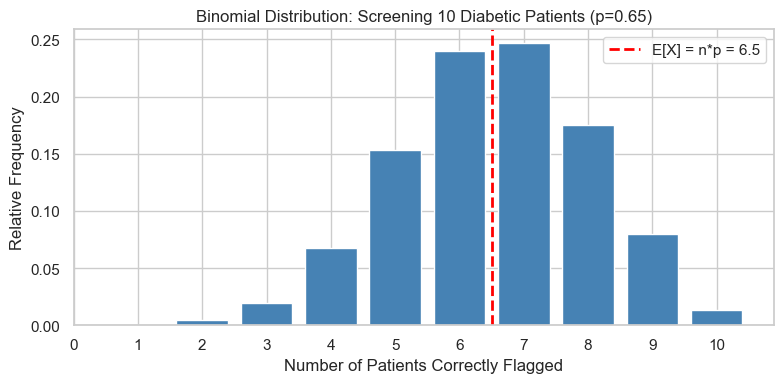

Observed  mean:     6.5222
Theoretical E[X]:   6.5000
Observed  variance: 2.2895
Theoretical Var[X]: 2.2750


In [20]:
# TODO: Generate and visualise a Binomial distribution.
#
# Scenario: A screening test has a 65% chance of correctly flagging a diabetic patient.
#           If we screen 10 diabetic patients, how many will be correctly flagged?
#
# Step 1: Generate 5000 samples from Binomial(n=10, p=0.65).
#         Use: np.random.binomial(n=10, p=0.65, size=5000)
# Step 2: Plot a bar chart of the frequency of each outcome (0 through 10).
#         Hint: use np.unique with return_counts=True, then ax.bar()
# Step 3: Mark the expected value E[X] = n*p as a vertical line.
# Step 4: Print: mean, variance, and the theoretical values (n*p and n*p*(1-p)).

np.random.seed(42)

# Step 1: Generate samples
n, p = 10, 0.65
binom_data = np.random.binomial(n=n, p=p, size=5000)

# Step 2: Plot bar chart of outcome frequencies
values, counts = np.unique(binom_data, return_counts=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(values, counts / counts.sum(), color='steelblue', edgecolor='white')

# Step 3: Mark expected value E[X] = n*p
expected = n * p
ax.axvline(expected, color='red', linestyle='--', lw=2, label=f'E[X] = n*p = {expected:.1f}')

ax.set_title('Binomial Distribution: Screening 10 Diabetic Patients (p=0.65)')
ax.set_xlabel('Number of Patients Correctly Flagged')
ax.set_ylabel('Relative Frequency')
ax.set_xticks(range(0, 11))
ax.legend()
plt.tight_layout()
plt.show()

# Step 4: Print mean, variance and theoretical values
mean_obs  = binom_data.mean()
var_obs   = binom_data.var()
mean_theo = n * p
var_theo  = n * p * (1 - p)

print(f'Observed  mean:     {mean_obs:.4f}')
print(f'Theoretical E[X]:   {mean_theo:.4f}')
print(f'Observed  variance: {var_obs:.4f}')
print(f'Theoretical Var[X]: {var_theo:.4f}')


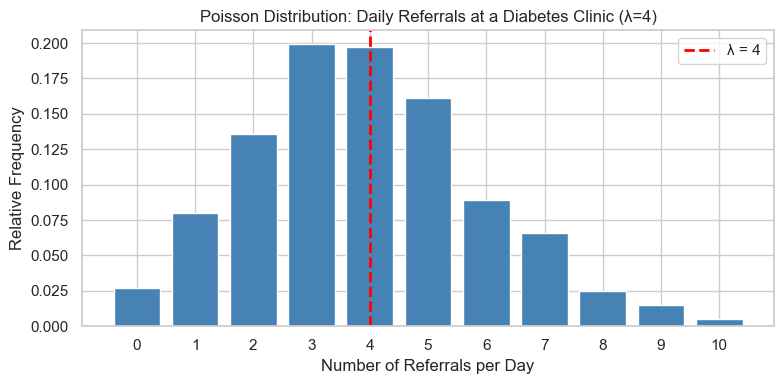

Simulated mean:     3.9230
Simulated variance: 3.9551
Theoretical mean = variance = λ = 4
Difference (mean - λ):     0.0770
Difference (variance - λ): 0.0449


In [21]:
# TODO: Generate and visualise a Poisson distribution.
#
# Scenario: A diabetes clinic receives an average of λ=4 new referrals per day.
#           Simulate 1000 days and plot the distribution of daily referral counts.
#
# Step 1: Generate 1000 samples from Poisson(lambda=4).
#         Use: np.random.poisson(lam=4, size=1000)
# Step 2: Plot a bar chart of counts (similar to Binomial above).
# Step 3: Mark λ as a vertical dashed line.
# Step 4: Print: simulated mean and variance. Compare to the theoretical
#         property of Poisson: mean = variance = λ.

np.random.seed(42)

# Step 1: Generate samples
lam = 4
poisson_data = np.random.poisson(lam=lam, size=1000)

# Step 2: Plot bar chart of counts
values, counts = np.unique(poisson_data, return_counts=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(values, counts / counts.sum(), color='steelblue', edgecolor='white')

# Step 3: Mark lambda as a vertical dashed line
ax.axvline(lam, color='red', linestyle='--', lw=2, label=f'λ = {lam}')

ax.set_title('Poisson Distribution: Daily Referrals at a Diabetes Clinic (λ=4)')
ax.set_xlabel('Number of Referrals per Day')
ax.set_ylabel('Relative Frequency')
ax.set_xticks(range(0, poisson_data.max() + 1))
ax.legend()
plt.tight_layout()
plt.show()

# Step 4: Print simulated mean and variance, compare to theoretical
mean_obs = poisson_data.mean()
var_obs  = poisson_data.var()

print(f'Simulated mean:     {mean_obs:.4f}')
print(f'Simulated variance: {var_obs:.4f}')
print(f'Theoretical mean = variance = λ = {lam}')
print(f'Difference (mean - λ):     {abs(mean_obs - lam):.4f}')
print(f'Difference (variance - λ): {abs(var_obs  - lam):.4f}')

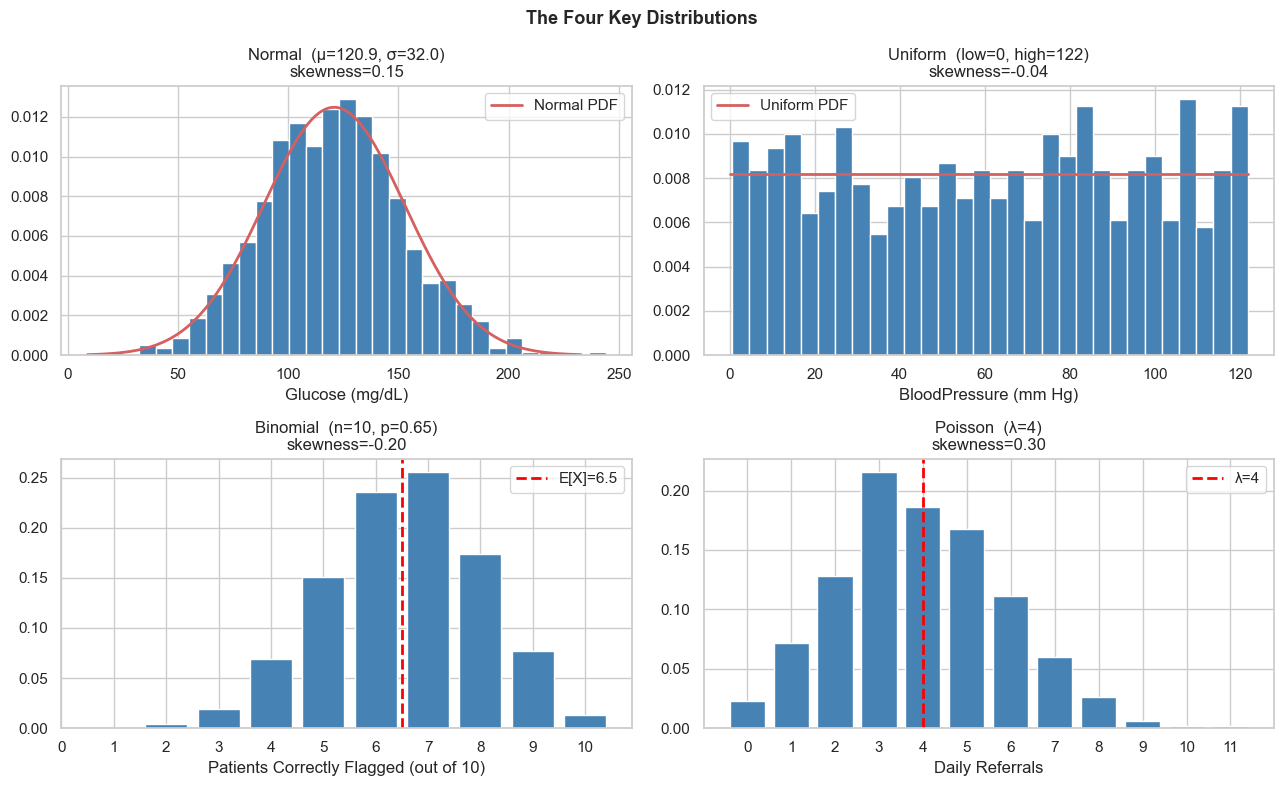

In [22]:
# TODO: Create a 2×2 summary grid showing all four distributions:
#   Top-left:     Normal   (μ = df['Glucose'].mean(), σ = df['Glucose'].std())
#   Top-right:    Uniform  (same range as BloodPressure)
#   Bottom-left:  Binomial (n=10, p=0.65, 5000 samples)
#   Bottom-right: Poisson  (λ=4, 1000 samples)
#
# Each panel must include:
#   - A descriptive title with the distribution name and parameters
#   - The skewness value in the title
#   - Appropriate x-axis label
# For the Normal panel: if you overlay the PDF curve, use
#   x = np.linspace(mu - 3.5*sigma, mu + 3.5*sigma, 300)
# NOT normal_data.min()/max() — the PDF range should be defined by the
# distribution parameters, not by what one random sample happened to produce.

np.random.seed(42)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# --- Top-left: Normal ---
mu, sigma = df['Glucose'].mean(), df['Glucose'].std()
normal_data = np.random.normal(loc=mu, scale=sigma, size=768)
axes[0, 0].hist(normal_data, bins=30, color='steelblue', edgecolor='white', density=True)
x = np.linspace(mu - 3.5 * sigma, mu + 3.5 * sigma, 300)
axes[0, 0].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', lw=2, label='Normal PDF')
axes[0, 0].set_title(f'Normal  (μ={mu:.1f}, σ={sigma:.1f})\nskewness={stats.skew(normal_data):.2f}')
axes[0, 0].set_xlabel('Glucose (mg/dL)')
axes[0, 0].legend()

# --- Top-right: Uniform ---
low, high = df['BloodPressure'].min(), df['BloodPressure'].max()
uniform_data = np.random.uniform(low=low, high=high, size=768)
axes[0, 1].hist(uniform_data, bins=30, color='steelblue', edgecolor='white', density=True)
x_u = np.linspace(low, high, 300)
axes[0, 1].plot(x_u, stats.uniform.pdf(x_u, loc=low, scale=high - low), 'r-', lw=2, label='Uniform PDF')
axes[0, 1].set_title(f'Uniform  (low={low:.0f}, high={high:.0f})\nskewness={stats.skew(uniform_data):.2f}')
axes[0, 1].set_xlabel('BloodPressure (mm Hg)')
axes[0, 1].legend()

# --- Bottom-left: Binomial ---
n, p = 10, 0.65
binom_data = np.random.binomial(n=n, p=p, size=5000)
values, counts = np.unique(binom_data, return_counts=True)
axes[1, 0].bar(values, counts / counts.sum(), color='steelblue', edgecolor='white')
axes[1, 0].axvline(n * p, color='red', linestyle='--', lw=2, label=f'E[X]={n*p:.1f}')
axes[1, 0].set_title(f'Binomial  (n={n}, p={p})\nskewness={stats.skew(binom_data):.2f}')
axes[1, 0].set_xlabel('Patients Correctly Flagged (out of 10)')
axes[1, 0].set_xticks(range(0, 11))
axes[1, 0].legend()

# --- Bottom-right: Poisson ---
lam = 4
poisson_data = np.random.poisson(lam=lam, size=1000)
values_p, counts_p = np.unique(poisson_data, return_counts=True)
axes[1, 1].bar(values_p, counts_p / counts_p.sum(), color='steelblue', edgecolor='white')
axes[1, 1].axvline(lam, color='red', linestyle='--', lw=2, label=f'λ={lam}')
axes[1, 1].set_title(f'Poisson  (λ={lam})\nskewness={stats.skew(poisson_data):.2f}')
axes[1, 1].set_xlabel('Daily Referrals')
axes[1, 1].set_xticks(range(0, poisson_data.max() + 1))
axes[1, 1].legend()

plt.suptitle('The Four Key Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### ✍️ Interpretation: Task 8

1. The Poisson distribution has a theoretical property that mean = variance = λ. Did your simulation confirm this? What does it imply if a real dataset has a much larger variance than mean (called overdispersion)?
2. Binomial and Poisson are both discrete. What is the key practical difference in *when* you would choose one over the other? Give one example from the diabetes clinical context for each.
3. Look at your four-panel plot. Which distribution has skewness closest to zero? What does zero skewness tell you about the relationship between mean, median, and mode?

> *Your answer here:*

---
# Task 9: Skewness: Measuring and Interpreting Asymmetry

Skewness quantifies how asymmetric a distribution is. Positive skew means the right tail is longer (a few very high values pull the mean upward). Negative skew means the left tail is longer.

Understanding skewness matters because:
- It tells you whether the mean is a reliable summary (it is not, for highly skewed data)
- Many ML models assume normally distributed inputs; skewed features may need transformation
- It reveals domain patterns (e.g. income, insurance claims, and biological assays are often right-skewed)

> **Goal:** Measure, visualise, and correct skewness in real dataset features. Understand the relationship between skewness and central tendency.

In [7]:
# ── Task 9 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# All 8 numeric feature columns — used throughout Task 9 for skewness analysis.
# 'Outcome' and 'DiabetesStatus' are excluded: Outcome is binary categorical,
# DiabetesStatus is a string label — neither has a meaningful skewness value.
NUMERIC_COLS = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
print('Ready')


Ready


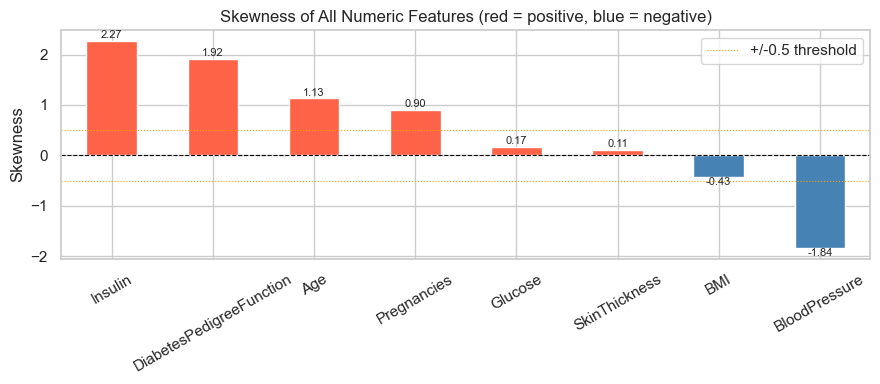


Skewness values:
Insulin                     2.272
DiabetesPedigreeFunction    1.920
Age                         1.130
Pregnancies                 0.902
Glucose                     0.174
SkinThickness               0.109
BMI                        -0.429
BloodPressure              -1.844
dtype: float64


In [8]:
# Provided: compute and visualise skewness for all numeric features

# df[NUMERIC_COLS].skew() computes the sample skewness for each column.
# Skewness formula: (1/n) * sum((x - mean)^3) / std^3
# Positive value -> right tail is longer (mean > median)
# Negative value -> left tail is longer  (mean < median)
# Near zero      -> approximately symmetric
skewness = df[NUMERIC_COLS].skew().sort_values(ascending=False).round(3)

fig, ax = plt.subplots(figsize=(9, 4))

# Colour bars: tomato (red) for positive skew, steelblue for negative skew.
# This makes the direction of asymmetry immediately visible.
colors = ['tomato' if s > 0 else 'steelblue' for s in skewness]
skewness.plot(kind='bar', ax=ax, color=colors, edgecolor='white')

# Reference lines to aid interpretation:
# Black dashed line at 0: perfect symmetry
# Orange dotted lines at +/-0.5: a common rule-of-thumb threshold —
#   |skewness| < 0.5  -> approximately symmetric (safe to use mean)
#   |skewness| > 0.5  -> noticeably skewed (prefer median)
#   |skewness| > 1.0  -> highly skewed (mean is misleading)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.axhline( 0.5, color='orange', linewidth=0.8, linestyle=':', label='+/-0.5 threshold')
ax.axhline(-0.5, color='orange', linewidth=0.8, linestyle=':')
ax.set_title('Skewness of All Numeric Features (red = positive, blue = negative)')
ax.set_ylabel('Skewness')
ax.tick_params(axis='x', rotation=30)
ax.legend()

# Annotate each bar with its exact value.
# Positive bars: label just above the bar top.
# Negative bars: label just below the bar top (hence the negative offset).
for i, v in enumerate(skewness):
    ax.text(i, v + (0.05 if v >= 0 else -0.15), f'{v:.2f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

print('\nSkewness values:')
print(skewness)


In [9]:
# TODO: For each numeric feature, compute the gap between mean and median.
# Print a table: Feature | Mean | Median | Gap (Mean − Median) | Skewness
# Sort by absolute gap descending.
#
# Observation: for positively skewed features, mean > median (gap > 0).
#              for negatively skewed features, mean < median (gap < 0).
#              for symmetric features, gap ≈ 0.

# YOUR CODE HERE


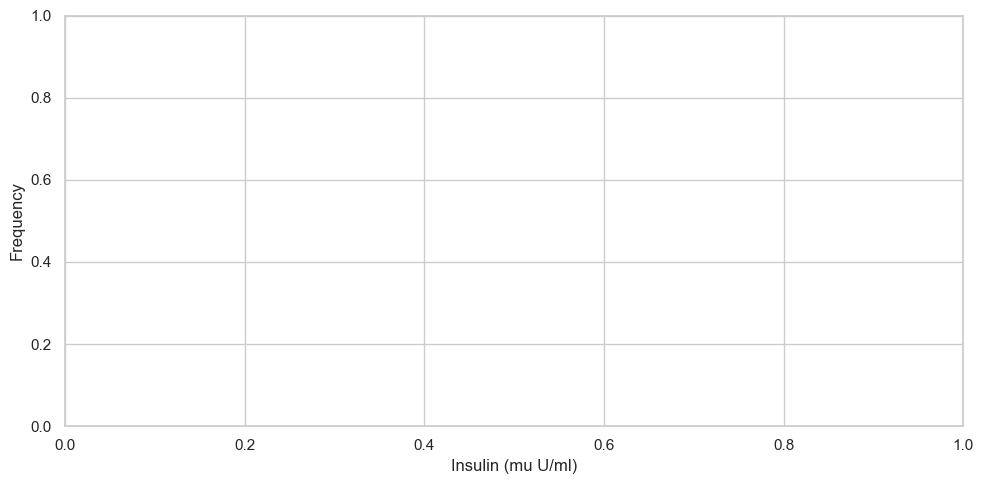

In [10]:
# TODO: Create a detailed anatomy plot for the most positively skewed feature: Insulin.
#
# Plot a histogram of Insulin (bins=30).
# Overlay three vertical lines:
#   - Mean       (red solid)    — label should show the numeric value
#   - Median     (green dashed) — label should show the numeric value
#   - Mode       (purple dotted)— label should show the numeric value
# Hint: use df['Insulin'].mean(), .median(), .mode()[0]
#
# Add an annotation arrow pointing to the right tail with the text:
#   'Long right tail (positive skew)'
# Hint for arrow: ax.annotate(text, xy=(...), xytext=(...), arrowprops=dict(arrowstyle='->'))
#
# Include the skewness value in the title.

fig, ax = plt.subplots(figsize=(10, 5))

# YOUR CODE HERE

ax.set_xlabel('Insulin (mu U/ml)')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()


In [11]:
# TODO: Apply a log transformation to reduce skewness in Insulin.
#
# Insulin contains zeros (missing values encoded as 0).
# Replace zeros with NaN first, then apply np.log1p() which computes log(1 + x)
# and is safe for values >= 0.
#
# Step 1: Create insulin_clean by replacing zeros with NaN, then dropping NaN.
# Step 2: Apply log1p to get insulin_log.
# Step 3: Plot side-by-side histograms: original (clean, zeros removed) | log-transformed.
#         Show mean, median, and skewness on each panel.
# Step 4: Print a comparison table:
#         | Version      | Mean   | Median | Skewness |
#         | Original     | ...    | ...    | ...      |
#         | Log-Transformed | ... | ...    | ...      |

# YOUR CODE HERE


In [12]:
# TODO: Match each real feature to its closest theoretical distribution.
#
# Complete the dictionary below by replacing each '???' with one of:
# 'Normal', 'Uniform', 'Binomial', 'Poisson', 'Right-skewed (not standard)', 'Left-skewed (not standard)'
#
# Use the skewness values and histogram shapes from the plots above to decide.
# Then print the dictionary as a formatted table.

distribution_match = {
    'Glucose':                  {'Closest distribution': '???', 'Reason': '???'},
    'BloodPressure':            {'Closest distribution': '???', 'Reason': '???'},
    'Insulin':                  {'Closest distribution': '???', 'Reason': '???'},
    'BMI':                      {'Closest distribution': '???', 'Reason': '???'},
    'DiabetesPedigreeFunction': {'Closest distribution': '???', 'Reason': '???'},
    'Age':                      {'Closest distribution': '???', 'Reason': '???'},
    'Pregnancies':              {'Closest distribution': '???', 'Reason': '???'},
}

# YOUR CODE HERE (print as a DataFrame)


### ✍️ Interpretation: Task 9

1. From your mean–median gap table: does the sign of the gap always match the sign of the skewness? Explain mathematically why a positive skew pulls the mean above the median.
2. After the log transformation of Insulin: by how much did the skewness decrease? Did the transformation make the mean and median closer together? Why is this useful before applying some machine learning models?
3. You matched features to theoretical distributions. Which feature was hardest to classify, and why? What additional information or test would help you make a more rigorous decision?

> *Your answer here:*

---
## 📋 Module D: Handoff Summary

| Item | Your finding |
|---|---|
| Most positively skewed feature (and value) | ??? (skewness = ???) |
| Feature closest to Normal distribution | ??? |
| Insulin skewness: before vs after log transform | Before: ???, After: ??? |
| Mean–Median gap direction rule | Positive skew → mean ??? median |
| Binomial simulation: E[X] theoretical vs simulated | Theoretical: ???, Simulated: ??? |
| Key insight to share with the group | ??? |

> Fill in the table above before merging with the group.